# De Bruijn Graph Traversal

Reconstruct a short string from its multiset of k-mers using an Eulerian trail.

A k-mer is a directed edge between its length k−1 prefix and suffix. Repeated edges carry multiplicity. Hierholzer’s traversal uses each edge once. Different trails can spell different strings with the same observations.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import kmers, euler_spelling
from collections import Counter
import networkx as nx

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Input ATGATCATGA | recovered ATCATGATGA
Edges traversed 8


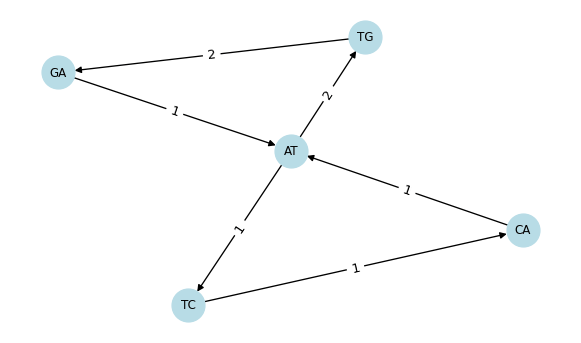

In [2]:
s = "ATGATCATGA"
k = 3
recovered, path = euler_spelling(s, k)
assert Counter(kmers(s, k)) == Counter(kmers(recovered, k))
print("Input", s, "| recovered", recovered)
print("Edges traversed", len(path) - 1)
G = nx.DiGraph()
for w, n in Counter(kmers(s, k)).items():
    G.add_edge(w[:-1], w[1:], weight=n)
p = nx.spring_layout(G, seed=17)
fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
nx.draw_networkx(G, p, ax=ax, node_color="#b8dce6", node_size=620, arrows=True, font_size=9)
nx.draw_networkx_edge_labels(G, p, ax=ax, edge_labels=nx.get_edge_attributes(G, "weight"))
ax.axis("off")
plt.show()

## Interpreting the result

The edge-multiset assertion is the reconstruction criterion. Repeats make the original order ambiguous even in this error-free example.

## Exercise

Find two different strings with the same multiset of length-three substrings.

## References

[Pevzner, Tang and Waterman, Eulerian paths in assembly (2001)](https://doi.org/10.1073/pnas.171285098)